# F2.1 — Figuras del techo 5D (adenda)

Figuras de apoyo de la tarea F2.1 (`results/f21_techo5d/`, `docs/bitacora/F2.1.md`). **No cambian resultados ni decisiones.**

Reglas que sigue este notebook:

- **Toda cifra que aparece en las gráficas se lee de** `results/f21_techo5d/*.csv`, `results/predictions/referencia/` y `results/canonical_numbers.json`. El notebook no recalcula ninguna cifra del reporte.
- **Prohibido usar test.** Las predicciones se filtran a `split == 'val'`, y `sin_test()` detiene el notebook si algún DataFrame usado en una figura contiene filas de test. Ninguna figura muestra test.
- Las figuras 1–6 se dibujan en escala de grises. Solo la figura 7, ilustrativa, usa color.
- **Única operación de modelo (figura 5):** las 3 muestras de validación en que `predict()` y `p_dep > 0.5` difieren no se archivaron. Para *localizarlas*, se reajusta el SVM seleccionado solo con `train`, con los hiperparámetros de su manifiesto. Antes de usarlo se verifica que reproduce exactamente el `p_dep` archivado en validación. El número de casos (3) se lee de `results/f21_techo5d/f21_techo5d.log` y solo se comprueba.
- Exportación: PDF y PNG a 300 dpi en `reports/figures/f21/`, con `src/viz/style.py`.

In [ ]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():          # nbconvert ejecuta desde notebooks/
    REPO = REPO.parent
sys.path[:0] = [str(REPO), str(REPO / 'src'), str(REPO / 'src' / 'training')]

import paths
from umap_io import load_umap_arrays, sha256
from viz import style

style.apply()
RES = REPO / 'results' / 'f21_techo5d'
PRED = REPO / 'results' / 'predictions' / 'referencia'
FIG = REPO / 'reports' / 'figures' / 'f21'
FAMS = ['logreg', 'svm_rbf', 'rf', 'gbm', 'mlp']
FAM_LABEL = {'logreg': 'LogReg', 'svm_rbf': 'SVM-RBF', 'rf': 'Random Forest', 'gbm': 'Gradient boosting', 'mlp': 'MLP'}
G_DARK, G_MID, G_LIGHT = style.INK, style.INK_SECONDARY, style.MUTED


def sin_test(*dfs):
    # Detiene el notebook si algún DataFrame de una figura tiene filas de test
    for df in dfs:
        if 'split' in df.columns:
            assert not (df['split'] == 'test').any(), 'PROHIBIDO: filas de test en una figura'


def guardar(fig, nombre):
    FIG.mkdir(parents=True, exist_ok=True)
    rutas = []
    for ext in ('pdf', 'png'):
        p = FIG / f'{nombre}.{ext}'
        fig.savefig(p, dpi=style.DPI, format=ext)
        rutas.append(p.relative_to(REPO).as_posix())
    print('\n'.join(rutas))

## Insumos

In [2]:
rejilla = pd.read_csv(RES / 'rejilla_completa.csv')
seleccion = pd.read_csv(RES / 'seleccion.csv')
rejilla['combo'] = rejilla['combinacion'].map(json.loads)
seleccion['combo'] = seleccion['combinacion'].map(json.loads)
assert list(seleccion['familia']) == FAMS and len(rejilla) == 128

canon = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))['numbers']
F1_FAM = {f: canon[f'ref.techo5d.{f}.f1_macro']['value']['val'] for f in FAMS}
F1_TECHO = canon['ref.techo5d.f1_macro']['value']['val']
F1_BETO = canon['ref.beto_exp41.f1_macro']['value']['val']
F1_768 = canon['ref.emb768_logreg.f1_macro']['value']['val']
CM_TECHO = canon['ref.techo5d.f1_macro']['confusion']['val']
TECHO = seleccion.loc[seleccion['techo'], 'familia'].item()
assert canon['ref.techo5d.f1_macro']['source']['path'].endswith(f'umap5d__{TECHO}__none__seed42.csv')
for f in FAMS:  # coherencia entre fuentes (sin recalcular)
    assert F1_FAM[f] == seleccion.set_index('familia').loc[f, 'f1_val']
assert F1_TECHO == F1_FAM[TECHO]

pred = pd.read_csv(PRED / f'umap5d__{TECHO}__none__seed42.csv', float_precision='round_trip')
pred = pred[pred['split'] == 'val'].reset_index(drop=True)   # PROHIBIDO usar test
sin_test(pred)
assert len(pred) == 114
manifest = json.loads((PRED / f'umap5d__{TECHO}__none__seed42.manifest.json').read_text(encoding='utf-8'))
N_DIF = int(re.search(r'difieren entre predict\(\) y p_dep > 0\.5: (\d+)/114',
                      (RES / 'f21_techo5d.log').read_text(encoding='utf-8')).group(1))
print(f'techo = {TECHO}; F1-Val = {F1_TECHO:.4f}; BETO val = {F1_BETO:.4f}; 768D val = {F1_768:.4f}; '
      f'casos predict ≠ p_dep>0.5 (log) = {N_DIF}')

techo = svm_rbf; F1-Val = 0.7246; BETO val = 0.7199; 768D val = 0.7305; casos predict ≠ p_dep>0.5 (log) = 3


## Figura 1 — F1-Val del mejor modelo de cada familia

reports/figures/f21/fig1_f1val_familias.pdf
reports/figures/f21/fig1_f1val_familias.png


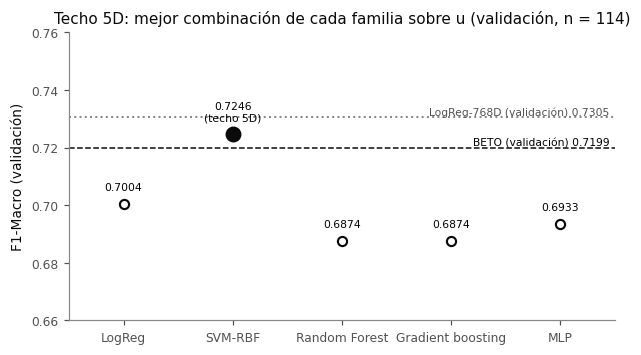

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
x = np.arange(len(FAMS))
for i, f in enumerate(FAMS):
    techo = f == TECHO
    ax.plot(i, F1_FAM[f], 'o', ms=9 if techo else 6, mfc=G_DARK if techo else 'white', mec=G_DARK, mew=1.4, zorder=3)
    ax.annotate(f'{F1_FAM[f]:.4f}' + ('\n(techo 5D)' if techo else ''), (i, F1_FAM[f]),
                xytext=(0, 9), textcoords='offset points', ha='center', fontsize=style.FONT_SIZES['annot'])
ax.axhline(F1_BETO, color=G_DARK, ls='--', lw=1)
ax.axhline(F1_768, color=G_LIGHT, ls=':', lw=1.3)
ax.text(len(FAMS) - 0.55, F1_BETO, f'BETO (validación) {F1_BETO:.4f}', va='bottom', ha='right', fontsize=style.FONT_SIZES['annot'])
ax.text(len(FAMS) - 0.55, F1_768, f'LogReg-768D (validación) {F1_768:.4f}', va='bottom', ha='right', fontsize=style.FONT_SIZES['annot'], color=G_MID)
ax.set_xticks(x, [FAM_LABEL[f] for f in FAMS])
ax.set_xlim(-0.5, len(FAMS) - 0.5)
ax.set_ylim(0.66, 0.76)
ax.set_ylabel('F1-Macro (validación)')
ax.set_title('Techo 5D: mejor combinación de cada familia sobre u (validación, n = 114)')
guardar(fig, 'fig1_f1val_familias')
plt.show()

## Figura 2 — Rejilla del SVM-RBF

reports/figures/f21/fig2_rejilla_svm.pdf
reports/figures/f21/fig2_rejilla_svm.png


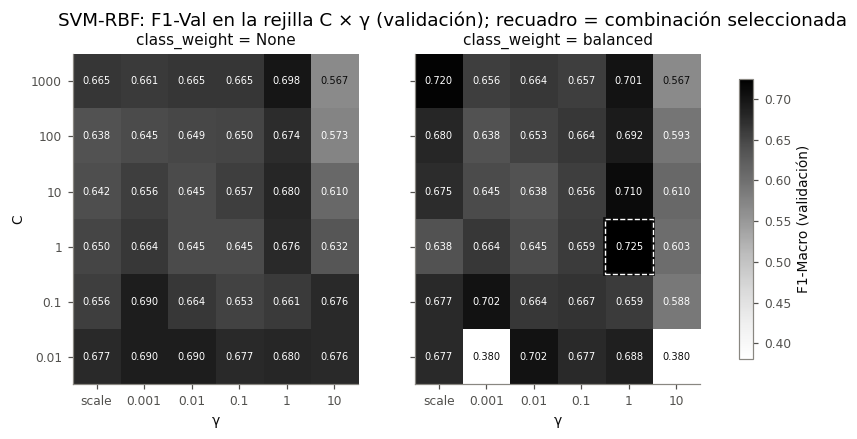

In [4]:
svm = rejilla[rejilla['familia'] == 'svm_rbf'].copy()
sin_test(svm)
svm['C'] = svm['combo'].map(lambda d: d['C'])
svm['gamma'] = svm['combo'].map(lambda d: d['gamma'])
svm['cw'] = svm['combo'].map(lambda d: d['class_weight'] or 'None')
Cs = sorted(svm['C'].unique())
gammas = ['scale'] + sorted(g for g in svm['gamma'].unique() if g != 'scale')
sel = seleccion.set_index('familia').loc['svm_rbf', 'combo']
vmin, vmax = svm['f1_val'].min(), svm['f1_val'].max()
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9), sharey=True)
for ax, cw in zip(axes, ['None', 'balanced']):
    M = np.full((len(Cs), len(gammas)), np.nan)
    for _, r in svm[svm['cw'] == cw].iterrows():
        M[Cs.index(r['C']), gammas.index(r['gamma'])] = r['f1_val']
    im = ax.imshow(M, cmap='Greys', vmin=vmin, vmax=vmax, aspect='auto', origin='lower')
    for i in range(len(Cs)):
        for j in range(len(gammas)):
            v = M[i, j]
            ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=6.5,
                    color='white' if (v - vmin) / (vmax - vmin) > 0.55 else G_DARK)
    if (sel['class_weight'] or 'None') == cw:
        i, j = Cs.index(sel['C']), gammas.index(sel['gamma'])
        ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=G_DARK, lw=2.4))
        ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec='white', lw=0.9, ls='--'))
    ax.set_xticks(range(len(gammas)), [g if g == 'scale' else f'{g:g}' for g in gammas])
    ax.set_yticks(range(len(Cs)), [f'{c:g}' for c in Cs])
    ax.set_xlabel('γ')
    ax.set_title(f'class_weight = {cw}')
axes[0].set_ylabel('C')
fig.colorbar(im, ax=axes, shrink=0.85, label='F1-Macro (validación)')
fig.suptitle('SVM-RBF: F1-Val en la rejilla C × γ (validación); recuadro = combinación seleccionada')
guardar(fig, 'fig2_rejilla_svm')
plt.show()

## Figura 3 — LogReg: F1-Val frente a C

reports/figures/f21/fig3_logreg_C.pdf
reports/figures/f21/fig3_logreg_C.png


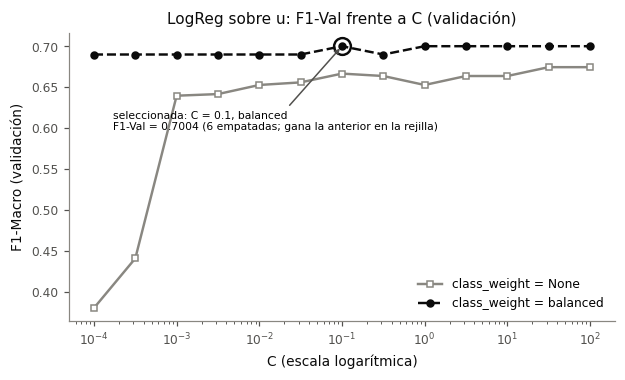

In [5]:
lr = rejilla[rejilla['familia'] == 'logreg'].copy()
sin_test(lr)
lr['C'] = lr['combo'].map(lambda d: d['C'])
lr['cw'] = lr['combo'].map(lambda d: d['class_weight'] or 'None')
sel = seleccion.set_index('familia').loc['logreg']
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for cw, sty in (('None', dict(color=G_LIGHT, ls='-', marker='s', mfc='white')),
                ('balanced', dict(color=G_DARK, ls='--', marker='o', mfc=G_DARK))):
    d = lr[lr['cw'] == cw].sort_values('C')
    ax.plot(d['C'], d['f1_val'], label=f'class_weight = {cw}', ms=4.5, **sty)
c_sel = sel['combo']['C']
ax.plot(c_sel, sel['f1_val'], 'o', ms=11, mfc='none', mec=G_DARK, mew=1.6)
ax.annotate(f'seleccionada: C = {c_sel:g}, {sel["combo"]["class_weight"]}\nF1-Val = {sel["f1_val"]:.4f} '
            f'({int(sel["n_empate_tolerancia"])} empatadas; gana la anterior en la rejilla)',
            (c_sel, sel['f1_val']), xytext=(-150, -55), textcoords='offset points',
            fontsize=style.FONT_SIZES['annot'], arrowprops=dict(arrowstyle='->', color=G_MID))
ax.set_xscale('log')
ax.set_xlabel('C (escala logarítmica)')
ax.set_ylabel('F1-Macro (validación)')
ax.set_title('LogReg sobre u: F1-Val frente a C (validación)')
ax.legend(loc='lower right')
guardar(fig, 'fig3_logreg_C')
plt.show()

## Figura 4 — Distribución del F1-Val de las 128 combinaciones

reports/figures/f21/fig4_distribucion_rejilla.pdf
reports/figures/f21/fig4_distribucion_rejilla.png


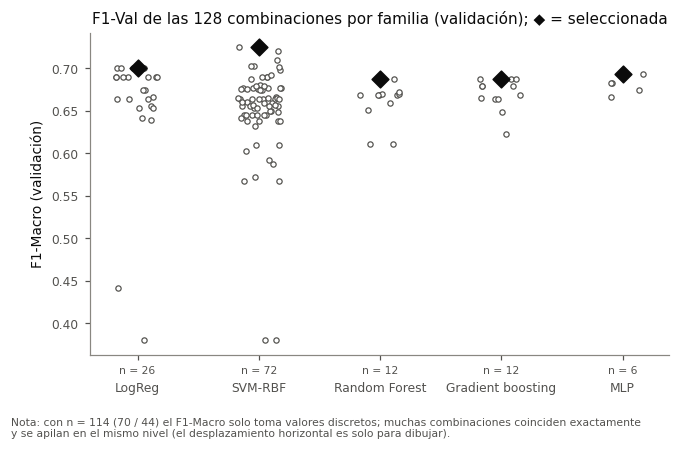

In [6]:
sin_test(rejilla)
rng = np.random.default_rng(0)   # solo desplazamiento horizontal para dibujar
fig, ax = plt.subplots(figsize=(6.8, 3.8))
for i, f in enumerate(FAMS):
    d = rejilla[rejilla['familia'] == f]
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(d)), d['f1_val'], s=12, facecolor='white', edgecolor=G_MID, lw=0.8, zorder=2)
    ax.scatter(i, F1_FAM[f], s=60, marker='D', color=G_DARK, zorder=3)
    ax.text(i, -0.06, f'n = {len(d)}', ha='center', fontsize=style.FONT_SIZES['annot'], color=G_MID,
            transform=ax.get_xaxis_transform())
ax.set_xticks(range(len(FAMS)), [FAM_LABEL[f] for f in FAMS])
ax.tick_params(axis='x', pad=14)
ax.set_ylabel('F1-Macro (validación)')
ax.set_title('F1-Val de las 128 combinaciones por familia (validación); ◆ = seleccionada')
fig.text(0.02, -0.04, 'Nota: con n = 114 (70 / 44) el F1-Macro solo toma valores discretos; muchas combinaciones '
         'coinciden exactamente\ny se apilan en el mismo nivel (el desplazamiento horizontal es solo para dibujar).',
         fontsize=style.FONT_SIZES['annot'], color=G_MID, va='top')
guardar(fig, 'fig4_distribucion_rejilla')
plt.show()

## Figura 5 — `p_dep` del techo en validación, por clase

Para localizar las muestras en que `predict()` y `p_dep > 0.5` difieren, se reajusta el SVM seleccionado solo con `train` y se verifica que reproduce exactamente el `p_dep` archivado. El número de casos se compara con el del log.

muestras que difieren: ['val_0019', 'val_0020', 'val_0063']


reports/figures/f21/fig5_pdep_techo.pdf
reports/figures/f21/fig5_pdep_techo.png


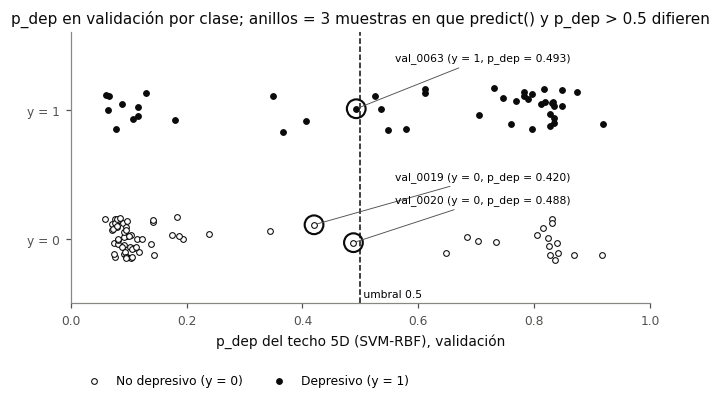

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

assert TECHO == 'svm_rbf' and manifest['config']['pipeline'].startswith('StandardScaler')
mpath = paths.umap_params_path()
dm = pd.read_csv(paths.DATA_MANIFEST)
assert sha256(mpath) == dm.loc[dm.logical_name == 'UMAP_PARAMS', 'sha256'].item()
U = load_umap_arrays(mpath)
Xtr, ytr = U['train']['params'].astype(np.float64), U['train']['labels'].astype(int)
Xva = U['val']['params'].astype(np.float64)                 # solo train y val; test no se lee
modelo = make_pipeline(StandardScaler(), SVC(**manifest['config']['estimator_params'])).fit(Xtr, ytr)
p_re = modelo.predict_proba(Xva)[:, int(np.flatnonzero(modelo.classes_ == 1)[0])]
assert np.array_equal(p_re, pred['p_dep'].values), 'el reajuste no reproduce el p_dep archivado'
difiere = modelo.predict(Xva) != (pred['p_dep'].values > 0.5).astype(int)
assert difiere.sum() == N_DIF == 3
print('muestras que difieren:', list(pred.loc[difiere, 'sample_id']))

sin_test(pred)
fig, ax = plt.subplots(figsize=(6.8, 3.2))
ypos = pred['y_true'].values + rng.uniform(-0.17, 0.17, len(pred))   # desplazamiento solo para dibujar
for y, lab in ((0, 'No depresivo (y = 0)'), (1, 'Depresivo (y = 1)')):
    m = (pred['y_true'] == y).values
    ax.scatter(pred['p_dep'][m], ypos[m], s=14, facecolor=G_DARK if y else 'white', edgecolor=G_DARK, lw=0.7, label=lab, zorder=2)
marcadas = sorted(np.flatnonzero(difiere), key=lambda i: -ypos[i])   # de arriba abajo
for i, h in zip(marcadas, [1.40, 0.48, 0.30]):   # alturas fijas de las etiquetas, en zonas vacías
    x, yy = pred.loc[i, 'p_dep'], ypos[i]
    ax.scatter(x, yy, s=150, facecolor='none', edgecolor=G_DARK, lw=1.4, zorder=3)
    ax.annotate(f"{pred.loc[i, 'sample_id']} (y = {int(pred.loc[i, 'y_true'])}, p_dep = {x:.3f})", (x, yy),
                xytext=(0.56, h), textcoords='data', ha='left', va='center',
                fontsize=style.FONT_SIZES['annot'], arrowprops=dict(arrowstyle='-', color=G_MID, lw=0.6))
ax.axvline(0.5, color=G_DARK, ls='--', lw=1)
ax.text(0.5, -0.45, ' umbral 0.5', fontsize=style.FONT_SIZES['annot'])
ax.set_yticks([0, 1], ['y = 0', 'y = 1'])
ax.set_ylim(-0.5, 1.6)
ax.set_xlim(0, 1)
ax.set_xlabel('p_dep del techo 5D (SVM-RBF), validación')
ax.set_title(f'p_dep en validación por clase; anillos = {N_DIF} muestras en que predict() y p_dep > 0.5 difieren')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.22), ncol=2)
guardar(fig, 'fig5_pdep_techo')
plt.show()

## Figura 6 — Matriz de confusión del techo en validación

reports/figures/f21/fig6_confusion_techo.pdf
reports/figures/f21/fig6_confusion_techo.png


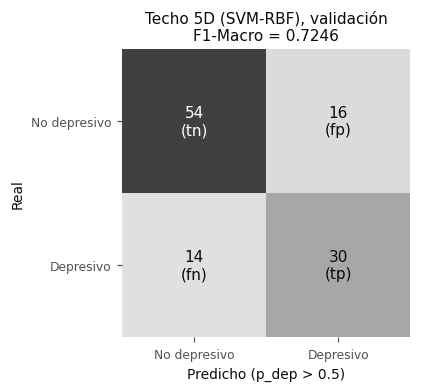

In [8]:
c = CM_TECHO
M = np.array([[c['tn'], c['fp']], [c['fn'], c['tp']]])
fig, ax = plt.subplots(figsize=(3.8, 3.4))
ax.imshow(M, cmap='Greys', vmin=0, vmax=M.max() * 1.25)
for (i, j), v in np.ndenumerate(M):
    name = [['tn', 'fp'], ['fn', 'tp']][i][j]
    ax.text(j, i, f'{v}\n({name})', ha='center', va='center', fontsize=10,
            color='white' if v > M.max() * 0.6 else G_DARK)
ax.set_xticks([0, 1], ['No depresivo', 'Depresivo'])
ax.set_yticks([0, 1], ['No depresivo', 'Depresivo'])
ax.set_xlabel('Predicho (p_dep > 0.5)')
ax.set_ylabel('Real')
ax.set_title(f'Techo 5D (SVM-RBF), validación\nF1-Macro = {F1_TECHO:.4f}')
ax.spines[:].set_visible(False)
guardar(fig, 'fig6_confusion_techo')
plt.show()

## Figura 7 — (Ilustrativa) Matriz de dispersión de u en entrenamiento

reports/figures/f21/fig7_dispersion_u_train.pdf
reports/figures/f21/fig7_dispersion_u_train.png


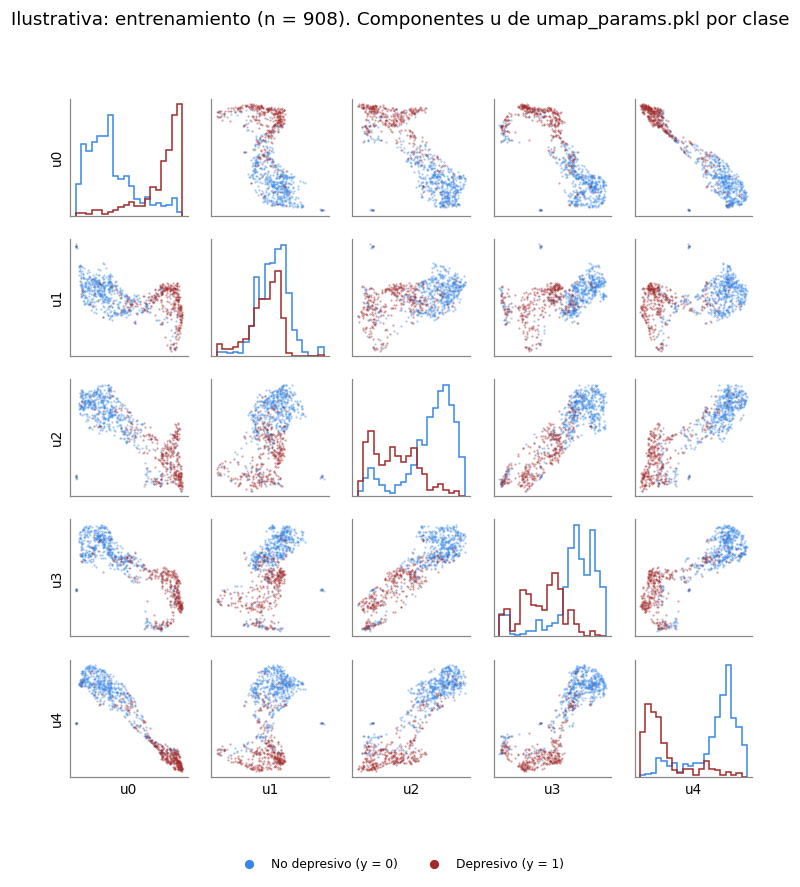

In [9]:
idx = pd.read_csv(paths.SAMPLE_INDEX, usecols=['sample_id', 'split', 'idx', 'y_true'])
tr = idx[idx['split'] == 'train'].sort_values('idx').reset_index(drop=True)
assert np.array_equal(tr['y_true'].values, ytr)
D = pd.DataFrame(Xtr, columns=[f'u{i}' for i in range(5)]).assign(split=tr['split'], y=tr['y_true'])
sin_test(D)
COL = {0: '#3987e5', 1: '#a32a2a'}
LAB = {0: 'No depresivo', 1: 'Depresivo'}
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for i in range(5):
    for j in range(5):
        ax = axes[i, j]
        for y in (0, 1):
            d = D[D['y'] == y]
            if i == j:
                ax.hist(d[f'u{i}'], bins=20, range=(0, 1), histtype='step', color=COL[y], lw=1.1)
            else:
                ax.scatter(d[f'u{j}'], d[f'u{i}'], s=2, color=COL[y], alpha=0.45, lw=0)
        ax.set_xticks([]); ax.set_yticks([])
        if i == 4: ax.set_xlabel(f'u{j}')
        if j == 0: ax.set_ylabel(f'u{i}')
handles = [plt.Line2D([], [], marker='o', ls='', color=COL[y], label=f'{LAB[y]} (y = {y})') for y in (0, 1)]
fig.legend(handles=handles, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.01))
fig.suptitle('Ilustrativa: entrenamiento (n = 908). Componentes u de umap_params.pkl por clase')
guardar(fig, 'fig7_dispersion_u_train')
plt.show()